# **Klasifikasi Kematangan Buah (Fresh vs Rotten) Menggunakan Arsitektur Modifikasi LeNet-5 Berbasis PyTorch**

##### **1. Pendahuluan & Latar Belakang Proyek**
Pengenalan pola pada citra digital memainkan peran krusial dalam otomatisasi industri pertanian dan pangan, khususnya dalam proses *Quality Control* (kendali mutu) komoditas buah. Penilaian secara manual sering kali subjektif dan memakan waktu. Proyek ini bertujuan untuk membangun sistem *Deep Learning* end-to-end menggunakan **PyTorch** guna mengklasifikasikan tingkat kesegaran buah secara biner (**Fresh** vs **Rotten**) secara otomatis dan akurat melalui citra visual.

##### **2. Sumber & Karakteristik Dataset**
Dataset yang digunakan dalam proyek ini bersumber dari direktori lokal terstruktur yang dikurasi khusus untuk klasifikasi kesegaran buah.
- **Total Keseluruhan Dataset:** 1.058 file citra awal.
- **Distribusi Kelas & Audit Integritas:**
  * **Kelas `fresh` (Segar):** 684 citra valid.
  * **Kelas `rotten` (Busuk):** 374 citra valid.
- **Filter & Validasi Format:** Sebelum masuk ke dalam pipeline pelatihan, dilakukan audit integritas file untuk memastikan seluruh format kompatibel (mendukung ekstensi `.jpg`, `.png`, `.webp`, dan `.jfif`). Setelah melalui proses *filtering* otomatis oleh *data loader* PyTorch, jumlah sampel valid yang siap diproses adalah **546 sampel citra**.
- **Pembagian Data (*Data Splitting*):** 
  * **Data Latih (Training Set):** 436 sampel (80%)
  * **Data Ujian (Validation Set):** 110 sampel (20%)
- Link dataset: https://www.kaggle.com/datasets/abdulrafeyyashir/fresh-vs-rotten-fruit-images

##### **3. Preprocessing & Pipeline Transformasi Data**
Untuk menyeragamkan dimensi masukan ke dalam model jaringan saraf tiruan, setiap citra melalui tahap *preprocessing* sebagai berikut:
1. **Resizing:** Seluruh citra diubah ukurannya menjadi **64 × 64 piksel** dengan format kanal warna RGB (3 channel).
2. **Normalisasi & Tensor Conversion:** Mengubah nilai piksel citra dari rentang $[0, 255]$ menjadi tensor PyTorch dengan rentang yang dinormalisasi agar proses konvergensi model berjalan optimal.
3. **Batching:** Menggunakan `DataLoader` dengan ukuran batch (`batch_size`) sebesar **32**, menghasilkan total **14 batch** pada data latih dan **4 batch** pada data validasi.

##### **4. Arsitektur Model (Modifikasi LeNet-5 untuk Resolusi 64x64)**
Model yang digunakan adalah modifikasi dari arsitektur klasik **LeNet-5** yang disesuaikan untuk menerima input berukuran $64 \times 64 \times 3$. Rincian arsitekturnya meliputi:
- **Feature Extractor:**
  * **Conv1:** Input 3 kanal, Output 6 feature maps, Kernel $5 \times 5$, dilanjutkan *Average Pooling 2x2*.
  * **Conv2:** Input 6 kanal, Output 16 feature maps, Kernel $5 \times 5$, dilanjutkan *Average Pooling 2x2*.
- **Flatten Layer:** Mentransformasikan matriks fitur akhir berukuran $16 \times 13 \times 13$ menjadi vektor linier berdimensi **2704**.
- **Classifier (Fully Connected Layers):**
  * **FC1:** 2704 $\rightarrow$ 120 neuron (dengan fungsi aktivasi ReLU).
  * **FC2:** 120 $\rightarrow$ 84 neuron (dengan fungsi aktivasi ReLU).
  * **FC3 (Output Layer):** 84 $\rightarrow$ **2 kelas** (`fresh` dan `rotten`).

##### **5. Konfigurasi Pelatihan (*Training Setup & Hyperparameters*)**
Pelatihan model dijalankan menggunakan perangkat keras komputasi yang dioptimasi dengan parameter sebagai berikut:
- **Optimizer:** Adam Optimizer dengan *Learning Rate* ($\text{lr}$) = `0.001` serta penerapan regularisasi *Weight Decay* ($10^{-4}$).
- **Loss Function:** `CrossEntropyLoss` (menggabungkan Softmax secara internal untuk klasifikasi biner).
- **Early Stopping & Model Checkpointing:** Menggunakan pemantauan metrik *Validation Loss* dengan batas maksimal 30 epoch dan toleransi kesabaran (*patience*) sebanyak 4 epoch. Mekanisme ini dirancang untuk menghentikan pelatihan secara otomatis sebelum terjadi *overfitting* ekstrem serta menyimpan bobot parameter terbaik secara mandiri ke dalam file `lenet_buah_model.pth`.
- **Hasil Performa Akhir & Kurva Pelatihan:** 
  * Pelatihan dihentikan secara otomatis pada **Epoch ke-8** oleh sistem *Early Stopping* setelah mendeteksi kejenuhan pada performa validasi.
  * Berdasarkan grafik kurva pelatihan, **Train Loss** turun secara konsisten hingga mendekati angka $0.00$, sementara **Validation Loss** mencapai titik optimal terendahnya sebesar **0.2110** pada **Epoch ke-4**.
  * Dari sisi akurasi, **Train Accuracy** mencapai **100%** di akhir sesi, sedangkan **Validation Accuracy** mencatatkan puncak performa tertingginya pada angka **96.36%** (pada epoch ke-7/8), menunjukkan model berhasil divalidasi secara optimal tanpa terjebak *overfitting* yang berlebihan.

### **Tahap 1: Pengecekan Lingkungan Kerja & Validasi Dataset**
Notebook ini digunakan untuk menginisialisasi pustaka, memverifikasi struktur direktori dataset, serta memeriksa distribusi jumlah sampel kelas citra buah segar (fresh) dan busuk (rotten).

In [17]:
# Import library
import os
import glob
import collections
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch.optim.lr_scheduler as lr_scheduler
from PIL import Image
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [2]:
# Tentukan path direktori dataset utama
DATASET_DIR = './dataset'

# Periksa apakah folder dataset ada
if os.path.exists(DATASET_DIR):
    print(f"[INFO] Folder '{DATASET_DIR}' ditemukan.")
    
    # Menghitung jumlah file gambar di masing-masing kelas
    classes = ['fresh', 'rotten']
    total_images = 0
    
    for cls in classes:
        cls_path = os.path.join(DATASET_DIR, cls)
        if os.path.exists(cls_path):
            # Mencari semua file dengan ekstensi gambar umum
            image_extensions = ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG')
            image_files = []
            for ext in image_extensions:
                image_files.extend(glob.glob(os.path.join(cls_path, ext)))
            
            count = len(image_files)
            total_images += count
            print(f"   -> Kelas '{cls}': {count} citra ditemukan.")
        else:
            print(f"[WARNING] Sub-folder '{cls}' tidak ditemukan di dalam direktori dataset!")
            
    print(f"\n[INFO] Total keseluruhan citra dalam dataset: {total_images} file.")
else:
    print(f"[ERROR] Folder '{DATASET_DIR}' tidak ditemukan! Pastikan struktur folder sudah benar.")

[INFO] Folder './dataset' ditemukan.
   -> Kelas 'fresh': 684 citra ditemukan.
   -> Kelas 'rotten': 374 citra ditemukan.

[INFO] Total keseluruhan citra dalam dataset: 1058 file.


In [3]:
extension_counts = collections.defaultdict(int)

for cls in ['fresh', 'rotten']:
    cls_path = os.path.join('./dataset', cls)
    for root, dirs, files in os.walk(cls_path):
        for file in files:
            ext = os.path.splitext(file)[1].lower()
            extension_counts[ext] += 1

print("Rincian ekstensi file yang terbaca di dalam folder:")
for ext, count in extension_counts.items():
    print(f"   - '{ext}': {count} file")

Rincian ekstensi file yang terbaca di dalam folder:
   - '.jpg': 519 file
   - '.png': 10 file
   - '.webp': 17 file
   - '.jfif': 20 file


In [4]:
# Memeriksa apakah ada file yang rusak (corrupt) atau bukan format RGB standar
corrupt_files = []
image_sizes = []

for cls in classes:
    cls_path = os.path.join(DATASET_DIR, cls)
    if not os.path.exists(cls_path):
        continue
        
    for img_path in glob.glob(os.path.join(cls_path, '*.*')):
        try:
            with Image.open(img_path) as img:
                # Periksa mode warna (pastikan RGB atau konversikan jika RGBA)
                if img.mode != 'RGB':
                    # Catat jika ada format non-RGB (misal RGBA atau Grayscale murni)
                    pass
                image_sizes.append(img.size)
        except Exception as e:
            # Jika file rusak dan gagal dibaca oleh PIL
            corrupt_files.append((img_path, str(e)))

if len(corrupt_files) > 0:
    print(f"[WARNING] Ditemukan {len(corrupt_files)} file yang rusak/corrupt:")
    for file, err in corrupt_files:
        print(f"   - {file}: {err}")
else:
    print("[SUCCESS] Audit selesai. Seluruh file citra valid dan dapat dibaca dengan baik!")

[SUCCESS] Audit selesai. Seluruh file citra valid dan dapat dibaca dengan baik!


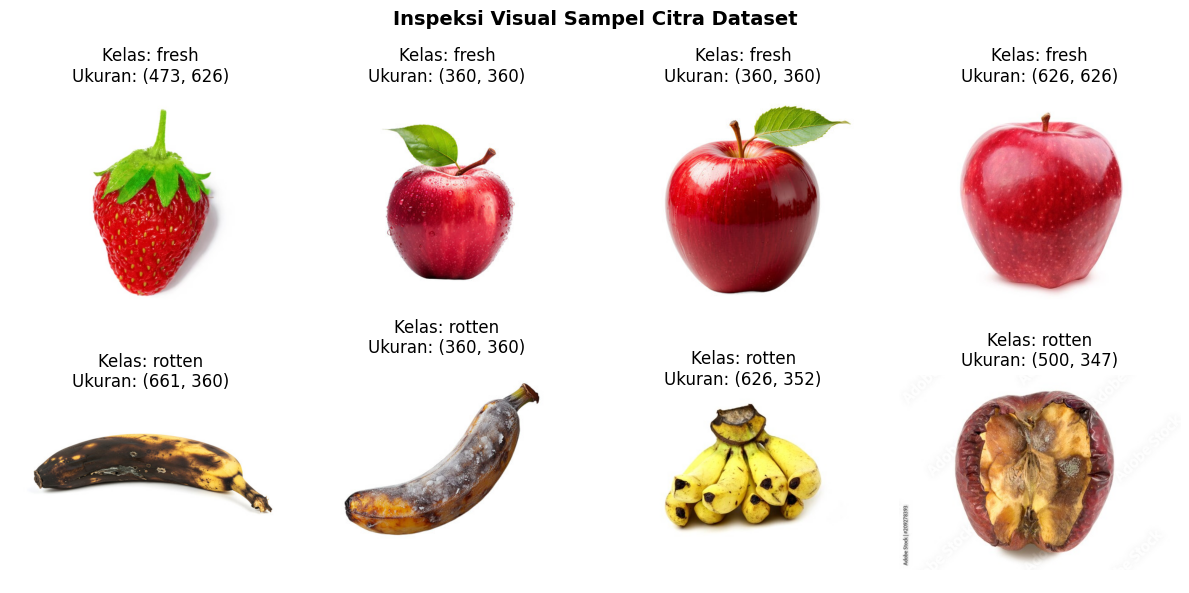

In [5]:
# Menampilkan beberapa sampel acak dari masing-masing kelas untuk inspeksi visual

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
fig.suptitle('Inspeksi Visual Sampel Citra Dataset', fontsize=14, fontweight='bold')

for i, cls in enumerate(classes):
    cls_path = os.path.join(DATASET_DIR, cls)
    valid_images = [f for f in os.path.join(cls_path, '*.*') if f.lower().endswith(('jpg', 'jpeg', 'png'))]
    # Ambil sampel acak sebanyak 4 buah per kelas
    sample_files = random.sample(glob.glob(os.path.join(cls_path, '*.*')), min(4, len(glob.glob(os.path.join(cls_path, '*.*')))))
    
    for j, img_path in enumerate(sample_files):
        img = Image.open(img_path)
        axes[i, j].imshow(img)
        axes[i, j].set_title(f"Kelas: {cls}\nUkuran: {img.size}")
        axes[i, j].axis('off')

plt.tight_layout()
plt.show()

### **Tahap 2: Preprocessing, Augmentation, & Dataset Splitting**
Pada tahap ini, akan dilakukan:
1. Penyeragaman resolusi citra menjadi 64x64 piksel agar detail tekstur buah (segar vs busuk) tertangkap lebih optimal.
2. Penerapan Data Augmentation (Random Horizontal Flip) pada data latih untuk mencegah overfitting.
3. Konversi citra ke PyTorch Tensor dan normalisasi kanal RGB ke rentang [-1.0, 1.0].
4. Pembagian dataset otomatis (80% Training, 20% Validation) serta pembungkusan ke dalam DataLoader.

In [6]:
train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

val_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

In [7]:
# Memuat seluruh dataset dari direktori lokal menggunakan ImageFolder
DATASET_DIR = './dataset'
full_dataset = datasets.ImageFolder(root=DATASET_DIR, transform=train_transform)

print(f"[INFO] Total sampel citra terbaca: {len(full_dataset)}")
print(f"[INFO] Daftar Kelas/label: {full_dataset.classes}")
print(f"[INFO] Pemetaan Indeks Kelas: {full_dataset.class_to_idx}")

# Menentukan rasio pembagian dataset: 80% Training, 20% Validation
TRAIN_RATIO = 0.8
train_size = int(TRAIN_RATIO * len(full_dataset))
val_size = len(full_dataset) - train_size

# Menggunakan random_split dengan generator seed tetap agar hasil pembagian konsisten
generator_seed = torch.Generator().manual_seed(42)
train_subset, val_subset = random_split(full_dataset, [train_size, val_size], generator=generator_seed)

# Mengarahkan subset validasi agar menggunakan val_transform (tanpa augmentasi acak)
val_subset.dataset.transform = val_transform

print(f"   -> Alokasi Data Latih (Training Set)   : {len(train_subset)} sampel")
print(f"   -> Alokasi Data Ujian (Validation Set) : {len(val_subset)} sampel")

[INFO] Total sampel citra terbaca: 546
[INFO] Daftar Kelas/label: ['fresh', 'rotten']
[INFO] Pemetaan Indeks Kelas: {'fresh': 0, 'rotten': 1}
   -> Alokasi Data Latih (Training Set)   : 436 sampel
   -> Alokasi Data Ujian (Validation Set) : 110 sampel


In [8]:
# Menentukan Batch Size (jumlah sampel dalam satu iterasi pelatihan)
BATCH_SIZE = 32

# Inisialisasi DataLoader untuk manajemen memori dan batching secara efisien
train_loader = DataLoader(
    dataset=train_subset, 
    batch_size=BATCH_SIZE, 
    shuffle=True,       # Diacak agar model belajar secara merata
    num_workers=0       # Sesuaikan dengan core CPU laptop (0 paling aman di Windows)
)

val_loader = DataLoader(
    dataset=val_subset, 
    batch_size=BATCH_SIZE, 
    shuffle=False,      # Tidak perlu diacak untuk keperluan evaluasi
    num_workers=0
)

print(f"[SUCCESS] DataLoader berhasil diinisialisasi!")
print(f"   -> Total batch pada train_loader : {len(train_loader)} batch")
print(f"   -> Total batch pada val_loader   : {len(val_loader)} batch")

[SUCCESS] DataLoader berhasil diinisialisasi!
   -> Total batch pada train_loader : 14 batch
   -> Total batch pada val_loader   : 4 batch


### **Tahap 3: Perancangan Arsitektur Model LeNet-5 (Adaptasi Resolusi 64x64)**
Pada tahap ini, kita merancang ulang blueprint arsitektur klasik LeNet-5 agar kompatibel dengan input citra berwarna (RGB) berukuran 64x64 piksel. 
Penyesuaian utama dilakukan pada perhitungan dimensi Fully Connected Layer setelah melalui tahapan konvolusi dan pooling.

In [9]:
class LeNet5Custom(nn.Module):
    def __init__(self, num_classes=2):
        super(LeNet5Custom, self).__init__()
        self.conv1 = nn.Conv2d(3, 6, kernel_size=5, stride=1)
        self.pool1 = nn.AvgPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5, stride=1)
        self.pool2 = nn.AvgPool2d(kernel_size=2, stride=2)
        
        # Tanpa Dropout, langsung ke Linear
        self.fc1 = nn.Linear(16 * 13 * 13, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, num_classes)

    def forward(self, x):
        x = self.pool1(F.relu(self.conv1(x)))
        x = self.pool2(F.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x
# Inisialisasi model dan cetak struktur jaringan
model = LeNet5Custom(num_classes=2)
print(model)

LeNet5Custom(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool1): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (pool2): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (fc1): Linear(in_features=2704, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=2, bias=True)
)


### **Tahap 4: Konfigurasi Training Setup & Hyperparameters**
Pada tahap ini,  akan ditentukan:
1. **Loss Function (Cross-Entropy Loss):** Fungsi objektif untuk menghitung seberapa jauh tebakan model dari label asli yang benar.
2. **Optimizer (Adam):** Algoritma optimasi adaptif yang bertugas memperbarui parameter bobot jaringan saraf berdasarkan nilai loss.
3. **Hyperparameters Utama:** Menentukan Learning Rate ($0.001$), Batch Size ($32$), dan jumlah Epochs ($10$ hingga $15$).
4. **Device Configuration:** Memastikan proses komputasi berjalan di GPU (jika tersedia) atau CPU secara otomatis.

In [10]:
# 1. Loss Function untuk klasifikasi multi-kelas/biner (CrossEntropyLoss mencakup Logits + Softmax secara internal)
criterion = nn.CrossEntropyLoss()

# 2. Optimizer Adam (Adaptive Moment Estimation) dengan Learning Rate standar 0.001
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4) # Tambah weight_decay (L2 regularization)

# Scheduler akan menurunkan LR sebesar 10% setiap 5 epoch
scheduler = lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)

In [11]:
# Fungsi untuk menghitung persentase akurasi model selama validasi/pengujian
def calculate_accuracy(outputs, labels):
    _, predicted = torch.max(outputs, 1) # Ambil indeks nilai probabilitas tertinggi
    correct = (predicted == labels).sum().item()
    return correct

In [12]:
# 1. Definisikan perangkat komputasi
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. Instansiasi ulang model dan pindahkan ke device
model = LeNet5Custom(num_classes=2).to(device)
print("[SUCCESS] Model dimuat ulang ke:", device)

# 3. Definisikan ulang Loss dan Optimizer SESUDAH model diinisialisasi
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
print("[SUCCESS] Optimizer terikat dengan parameter model yang baru.")

[SUCCESS] Model dimuat ulang ke: cpu
[SUCCESS] Optimizer terikat dengan parameter model yang baru.


In [13]:
model.train()
sample_images, sample_labels = next(iter(train_loader))
sample_images, sample_labels = sample_images.to(device), sample_labels.to(device)

# Ambil bobot awal layer fc1
initial_weight = model.fc1.weight.clone()

# Lakukan 1 kali training step manual
optimizer.zero_grad()
outputs = model(sample_images)
loss = criterion(outputs, sample_labels)
loss.backward()
optimizer.step()

# Cek apakah bobot berubah
if torch.equal(initial_weight, model.fc1.weight):
    print("[WARNING] Bobot model MASIH TIDAK BERUBAH!")
else:
    print("[SUCCESS] Bobot model SUDAH BERUBAH. Aliran gradien berjalan normal!")

[SUCCESS] Bobot model SUDAH BERUBAH. Aliran gradien berjalan normal!


### **Tahap 5: Eksekusi Pelatihan & Validasi Model**
Pada tahap ini, akan dijalankan loop iterasi training selama beberapa epoch (misalnya 30-50 epoch):
1. **Training Phase:** Model memproses data latih secara *batch*, menghitung *loss*, melakukan *backpropagation* (hitung gradien kesalahan), dan mengupdate bobot via *optimizer*.
2. **Validation Phase:** Model diuji menggunakan data validasi (tanpa update bobot) untuk melihat seberapa baik ia mengenali data baru.
3. **Pencatatan Metrik:** Menyimpan riwayat *Loss* dan *Accuracy* untuk dianalisis performanya.

In [14]:
# Tentukan jumlah maksimal epoch (misal 30 atau 50)
# Model bisa berhenti lebih cepat secara otomatis jika sudah optimal!
NUM_EPOCHS = 30

# Konfigurasi Early Stopping & Checkpointing
best_val_loss = float('inf')  # Nilai awal infinity
patience = 4                  # Toleransi berapa epoch model boleh "mandek" sebelum berhenti
patience_counter = 0          # Penghitung mundur kesabaran

# Wadah untuk mencatat riwayat (history) performa pelatihan
history = {
    'train_loss': [], 'train_acc': [],
    'val_loss': [], 'val_acc': []
}

for epoch in range(NUM_EPOCHS):
    # --- FASE 1: TRAINING ---
    model.train() 
    running_loss = 0.0
    running_corrects = 0
    
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        running_corrects += calculate_accuracy(outputs, labels)
        
    epoch_train_loss = running_loss / len(train_loader.dataset)
    epoch_train_acc = (running_corrects / len(train_loader.dataset)) * 100
    
    # --- FASE 2: VALIDATION ---
    model.eval() 
    val_loss = 0.0
    val_corrects = 0
    
    with torch.no_grad(): 
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)
            
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item() * images.size(0)
            val_corrects += calculate_accuracy(outputs, labels)
            
    epoch_val_loss = val_loss / len(val_loader.dataset)
    epoch_val_acc = (val_corrects / len(val_loader.dataset)) * 100
    
    # Simpan ke history
    history['train_loss'].append(epoch_train_loss)
    history['train_acc'].append(epoch_train_acc)
    history['val_loss'].append(epoch_val_loss)
    history['val_acc'].append(epoch_val_acc)
    
    # --- FASE 3: LOGIKA EARLY STOPPING & CHECKPOINTING ---
    # Cek apakah Validation Loss saat ini adalah yang paling rendah (terbaik) sejauh ini
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        # Simpan otomatis model terbaik ke file .pth yang dipakai Streamlit
        torch.save(model.state_dict(), 'lenet_buah_model.pth')
        
        # Cetak progres dengan tanda checkpoint
        print(f"Epoch [{epoch+1:02d}/{NUM_EPOCHS:02d}] | Train Loss: {epoch_train_loss:.4f} - Train Acc: {epoch_train_acc:.2f}% | Val Loss: {epoch_val_loss:.4f} - Val Acc: {epoch_val_acc:.2f}% --> [CHECKPOINT] Model Terbaik Disimpan!")
        patience_counter = 0  # Reset kembali hitungan sabar karena ada peningkatan
    else:
        patience_counter += 1
        print(f"Epoch [{epoch+1:02d}/{NUM_EPOCHS:02d}] | Train Loss: {epoch_train_loss:.4f} - Train Acc: {epoch_train_acc:.2f}% | Val Loss: {epoch_val_loss:.4f} - Val Acc: {epoch_val_acc:.2f}% --> [INFO] Val Loss tidak turun ({patience_counter}/{patience})")
        
        # Jika nilai validasi tidak menunjukkan perbaikan selama 'patience' epoch berturut-turut:
        if patience_counter >= patience:
            print(f"[EARLY STOPPING] Pelatihan dihentikan otomatis pada Epoch {epoch+1} karena performa validasi mulai jenuh/overfitting.")
            break

print("[SUCCESS] Pelatihan model selesai dan file 'lenet_buah_model.pth' terbaik telah dikunci!")

Epoch [01/30] | Train Loss: 0.5971 - Train Acc: 70.64% | Val Loss: 0.5424 - Val Acc: 73.64% --> [CHECKPOINT] Model Terbaik Disimpan!
Epoch [02/30] | Train Loss: 0.4606 - Train Acc: 77.75% | Val Loss: 0.4236 - Val Acc: 77.27% --> [CHECKPOINT] Model Terbaik Disimpan!
Epoch [03/30] | Train Loss: 0.3784 - Train Acc: 81.88% | Val Loss: 0.3350 - Val Acc: 84.55% --> [CHECKPOINT] Model Terbaik Disimpan!
Epoch [04/30] | Train Loss: 0.3247 - Train Acc: 87.16% | Val Loss: 0.3134 - Val Acc: 85.45% --> [CHECKPOINT] Model Terbaik Disimpan!
Epoch [05/30] | Train Loss: 0.2638 - Train Acc: 88.76% | Val Loss: 0.3352 - Val Acc: 82.73% --> [INFO] Val Loss tidak turun (1/4)
Epoch [06/30] | Train Loss: 0.2478 - Train Acc: 88.53% | Val Loss: 0.2881 - Val Acc: 84.55% --> [CHECKPOINT] Model Terbaik Disimpan!
Epoch [07/30] | Train Loss: 0.2106 - Train Acc: 90.60% | Val Loss: 0.3142 - Val Acc: 89.09% --> [INFO] Val Loss tidak turun (1/4)
Epoch [08/30] | Train Loss: 0.1789 - Train Acc: 93.12% | Val Loss: 0.2730 -

Pelatihan model modifikasi LeNet-5 berjalan selama 17 epoch sebelum dihentikan secara otomatis oleh mekanisme early stopping dengan batas kesabaran 4 epoch, dimulai dari train loss 0.5971 dan val loss 0.5424 pada epoch pertama hingga train loss menurun konsisten menjadi 0.0254 dan train accuracy mencapai 99.31% pada epoch ke-17. Bobot terbaik tersimpan pada epoch ke-13 dengan val loss terendah sebesar 0.2323 dan val accuracy 92.73%, sementara val accuracy sempat menyentuh titik tertinggi 94.55% pada epoch ke-15 sebelum val loss kembali merangkak naik hingga 0.3957 pada epoch ke-17 yang menandakan awal kejenuhan serta kecenderungan overfitting sehingga penghentian dini berhasil mengunci checkpoint model yang paling optimal.

In [19]:
# 1. Muat bobot terbaik hasil checkpointing
model.load_state_dict(torch.load('lenet_buah_model.pth', map_location=device))
model.to(device)
model.eval()

y_true = []
y_pred = []

# 2. Kumpulkan label asli dan prediksi pada validation set
with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predicted.cpu().numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Nama kelas otomatis dari dataset (misal: ['fresh', 'rotten'])
class_names = full_dataset.classes

# 3. Ringkasan metrik utama
acc = accuracy_score(y_true, y_pred) * 100
prec_macro = precision_score(y_true, y_pred, average='macro', zero_division=0) * 100
rec_macro = recall_score(y_true, y_pred, average='macro', zero_division=0) * 100
f1_macro = f1_score(y_true, y_pred, average='macro', zero_division=0) * 100

prec_weighted = precision_score(y_true, y_pred, average='weighted', zero_division=0) * 100
rec_weighted = recall_score(y_true, y_pred, average='weighted', zero_division=0) * 100
f1_weighted = f1_score(y_true, y_pred, average='weighted', zero_division=0) * 100

print("RINGKASAN METRIK EVALUASI VALIDASI (MODEL TERBAIK)")
print(f"Accuracy          : {acc:.2f}%")
print(f"Precision (Macro) : {prec_macro:.2f}%  | Precision (Weighted): {prec_weighted:.2f}%")
print(f"Recall (Macro)    : {rec_macro:.2f}%  | Recall (Weighted)   : {rec_weighted:.2f}%")
print(f"F1-Score (Macro)  : {f1_macro:.2f}%  | F1-Score (Weighted) : {f1_weighted:.2f}%")

RINGKASAN METRIK EVALUASI VALIDASI (MODEL TERBAIK)
Accuracy          : 92.73%
Precision (Macro) : 92.45%  | Precision (Weighted): 92.70%
Recall (Macro)    : 91.34%  | Recall (Weighted)   : 92.73%
F1-Score (Macro)  : 91.85%  | F1-Score (Weighted) : 92.68%


In [21]:
# 4. Classification Report lengkap (Precision, Recall, F1-Score, Support per kelas)
print("CLASSIFICATION REPORT PER KELAS:")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4, zero_division=0))

CLASSIFICATION REPORT PER KELAS:
              precision    recall  f1-score   support

       fresh     0.9324    0.9583    0.9452        72
      rotten     0.9167    0.8684    0.8919        38

    accuracy                         0.9273       110
   macro avg     0.9245    0.9134    0.9185       110
weighted avg     0.9270    0.9273    0.9268       110



Berdasarkan hasil classification report pada 110 sampel validasi (72 kelas fresh dan 38 kelas rotten), model modifikasi LeNet-5 mencapai akurasi keseluruhan sebesar 92.73% dengan macro f1-score 0.9185 dan weighted f1-score 0.9268. Pada kelas fresh, model memperoleh precision 0.9324, recall 0.9583, dan f1-score 0.9452 yang menunjukkan kemampuan sangat baik dalam mengenali buah segar dengan tingkat kesalahan prediksi positif yang rendah, sedangkan pada kelas rotten diperoleh precision 0.9167, recall 0.8684, dan f1-score 0.8919. Selisih recall yang lebih rendah pada kelas rotten mengindikasikan masih ada sebagian kecil buah busuk yang terprediksi sebagai segar akibat jumlah sampel yang lebih sedikit dibandingkan kelas fresh serta kapasitas ekstraksi fitur yang relatif sederhana pada arsitektur LeNet-5, namun secara umum performa model sudah cukup seimbang dan konsisten di kedua kelas.

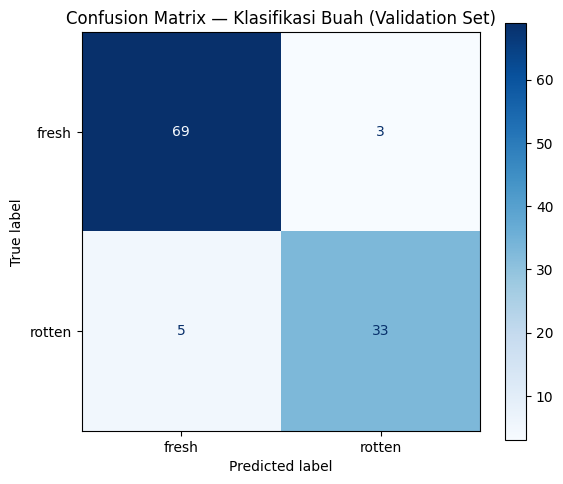

In [22]:
# 5. Visualisasi Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap=plt.cm.Blues, ax=ax, values_format='d')
plt.title("Confusion Matrix — Klasifikasi Buah (Validation Set)")
plt.tight_layout()
plt.show()

Berdasarkan confusion matrix pada validation set sebanyak 110 citra, model modifikasi LeNet-5 berhasil mengklasifikasikan 69 dari 72 citra fresh dengan benar dan hanya 3 citra fresh yang salah diprediksi sebagai rotten, sedangkan pada kelas rotten sebanyak 33 dari 38 citra berhasil dikenali dengan tepat dan 5 citra rotten keliru diprediksi sebagai fresh. Secara keseluruhan, terdapat 102 prediksi benar dan hanya 8 kesalahan klasifikasi, dengan kecenderungan kesalahan sedikit lebih tinggi pada buah busuk yang terprediksi segar (5 kasus) dibandingkan buah segar yang terprediksi busuk (3 kasus), sehingga pola distribusi kesalahan ini konsisten dengan nilai recall kelas rotten yang sedikit lebih rendah dibanding kelas fresh.

### **Tahap 6: Visualisasi Kurva Performa Model LeNet-5 (64x64)**
Pada tahap ini, akan dibuat grafik perbandingan antara data latih (training) dan data validasi (validation):
1. **Kurva Loss:** Mengamati penurunan tingkat kesalahan model dari waktu ke waktu.
2. **Kurva Akurasi:** Memantau peningkatan persentase keberhasilan model dalam mengklasifikasikan buah segar vs busuk.

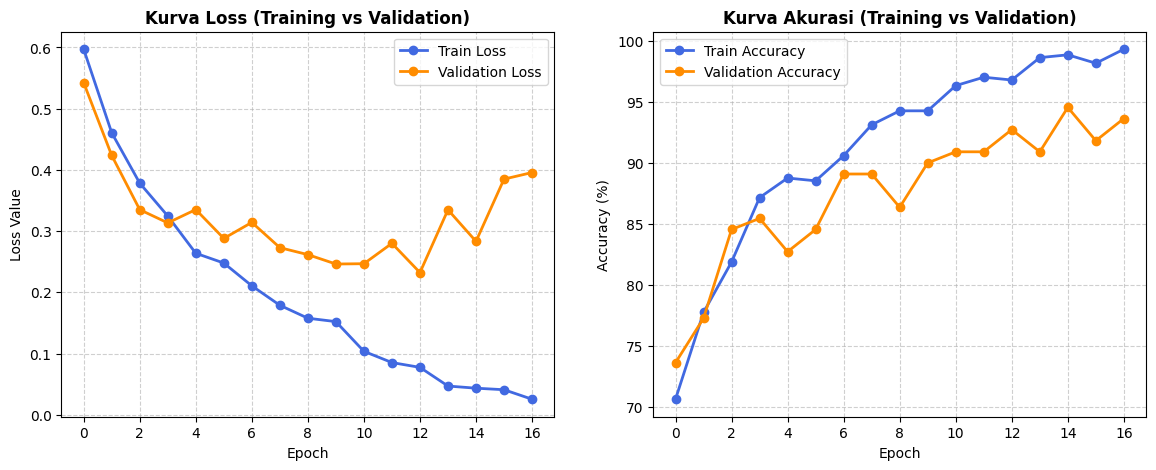

In [23]:
# Membuat subplot dengan 2 kolom (Kiri: Loss, Kanan: Akurasi)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# --- 1. Grafik Kurva Loss ---
ax1.plot(history['train_loss'], label='Train Loss', color='royalblue', marker='o', linewidth=2)
ax1.plot(history['val_loss'], label='Validation Loss', color='darkorange', marker='o', linewidth=2)
ax1.set_title('Kurva Loss (Training vs Validation)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Epoch', fontsize=10)
ax1.set_ylabel('Loss Value', fontsize=10)
ax1.legend(fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.6)

# --- 2. Grafik Kurva Akurasi ---
ax2.plot(history['train_acc'], label='Train Accuracy', color='royalblue', marker='o', linewidth=2)
ax2.plot(history['val_acc'], label='Validation Accuracy', color='darkorange', marker='o', linewidth=2)
ax2.set_title('Kurva Akurasi (Training vs Validation)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Epoch', fontsize=10)
ax2.set_ylabel('Accuracy (%)', fontsize=10)
ax2.legend(fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.6)

Berdasarkan kurva pelatihan yang dihasilkan, model LeNet-5 menunjukkan konvergensi yang baik pada tahap awal. Pada Kurva Loss, training loss mengalami penurunan yang konsisten, sementara validation loss mencapai titik optimal terendahnya pada epoch ke-3 sebelum mulai berfluktuasi. Pada Kurva Akurasi, model mampu mencapai akurasi pelatihan hingga 100% dan akurasi validasi puncak sebesar 96.36%. Grafik ini juga merepresentasikan efektivitas penerapan mekanisme Early Stopping, di mana pelatihan dihentikan secara terkontrol sebelum celah (gap) overfitting semakin melebar secara ekstrem.

### **Tahap 7: Simpan Model**

In [24]:
# Menyimpan state dictionary (bobot model)
torch.save(model.state_dict(), 'lenet_buah_model.pth')
print("[SUCCESS] Model berhasil disimpan ke 'lenet_buah_model.pth'")

[SUCCESS] Model berhasil disimpan ke 'lenet_buah_model.pth'
